# 3. WEEKLY MOMENTUM (ETHUSD) · ROBUSTNESS BATTERY & VALIDATION GATE

Multi-phase robustness battery and validation gate for **Weekly Momentum** on hourly Axi ETHUSD CFD bars, same structure as notebook 03 of Gotobi / Monday Effect / RSI2. The rules are the ones frozen in notebooks 01 and 02: **nothing is re-tuned here**.

### BATTERY
1. **Out-of-sample** performance (untouched data since `split.oos_start`), overlap-adjusted t-stat and the hard limit, ideal fraction and lot-adjusted at `CAPITAL`.
2. **Walk-forward** (fixed rules, 3y IS → 1y OOS).
3. **Block Monte Carlo** on the hourly MTM paths: robot size, 2x robot, and the **real lot-adjusted size** at `CAPITAL`.
4. **Monkey tests**: (A) random entries at any hour, (B) random signal weeks. Plus the **multiple-testing bar** (one-sided Bonferroni) for the trials counted and for the whole parameter grid.
5. **Stress and tails**: spread x2 / swap x2, break-even, best years / best 10 % of trades removed, bull years removed, eras, and an approximate stop test (the rule has **no stop**).
6. **Edge decay**: rolling mean / PF, PF by year and the z wear-and-tear protocol.
7. **Full validation gate** (`validation_gate.run_validation`).
8. **Verdict**: one PASS / FAIL table, with the weaknesses carried over from notebook 02 declared next to it.

### HONESTY NOTES
- **Trial count**: the long-only variant was chosen after seeing v1's full-sample results, so it is trial #2 on this dataset (`N_TRIALS`). Monkey B and the Bonferroni bar use it. The lookback x hold grid (810 cells) is a much larger family: the bar for it is printed as information.
- **OOS is not independent** of that choice: even with every check in PASS the variant stays a *conditional candidate* until it has forward data.
- **Overlap**: with `hold_days` > 7 consecutive trades overlap. Plain per-trade t-stats and the block bootstrap are optimistic; the t-stats used for decisions are Newey-West.
- Trades are generated once on the full history and split by **entry date** (same convention as notebook 01).

### STRATEGY PARAMETERS

In [1]:
VARIANT = "v2_ethusd_long"   # base variants: "v1_ethusd" (both legs) | "v2_ethusd_long" (long only)
HARD_LIMIT = 0.09
CAPITAL = 3_500.0            # account capital for the lot-adjusted checks (minimum lot 0.1 ETH)
N_TRIALS = 2                 # v1 + long-only variant on the same dataset

## 1. IMPORTS AND CONFIG

In [2]:
import sys, json, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def find_upwards(name, start=None, must_be_dir=True):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')
utils_path = str(find_upwards('utils') / 'utils')
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics
from metrics import sharpe_ratio, max_drawdown
from robustness import monte_carlo_block, grid_search, plateau_check, profit_factor
from edge_decay import rolling_pf, plot_rolling_pf, pf_by_year, edge_decay_summary
from validation_gate import run_validation, DEFAULTS as GATE
import weekly_momentum_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)
variant_config.EDGE_DIR = EDGE_DIR
assert (EDGE_DIR / "variants").is_dir()

cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
LOOKBACK, HOLD, ENTRY_DOW, ENTRY_HOUR = int(P["lookback_days"]), int(P["hold_days"]), P["entry_dow"], P["entry_hour"]
DIRECTION, COST_MODE, COST_BPS = P["direction"], P["cost_mode"], P["cost_bps_per_side"]
LOOKBACKS = [int(x) for x in cfg["grid"]["lookback_days_values"]]
HOLDS     = [int(x) for x in cfg["grid"]["hold_days_values"]]
CHOSEN    = (LOOKBACK, HOLD)
SIZE_FRAC = eng.ENGINE_DEFAULTS["size_fraction"]
SWAP_L0, SWAP_S0 = eng.ENGINE_DEFAULTS["swap_long_pct_annual"], eng.ENGINE_DEFAULTS["swap_short_pct_annual"]
PPY       = 365
SIZES     = {f"{SIZE_FRAC:.0%} (robot)": SIZE_FRAC, f"{2 * SIZE_FRAC:.0%} (2x robot)": 2 * SIZE_FRAC}   # first = official run
OFFICIAL  = next(iter(SIZES))

RULES = dict(lookback_days=LOOKBACK, hold_days=HOLD, entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR,
             direction=DIRECTION, cost_mode=COST_MODE, cost_bps_per_side=COST_BPS)
NAKED_DIR = "short_only" if DIRECTION == "short_only" else "long_only"

# ---- visual style (one dark theme for notebooks 02 and 03) ----
from IPython.display import display

BG, PANEL, GRIDC, TXT, SUB = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab"
GREEN, RED, ORANGE, BLUE, CYAN, GOLD = "#34d399", "#f0555a", "#f5a524", "#5468ff", "#38bdf8", "#f5c542"
plt.rcParams.update({"figure.facecolor": BG, "savefig.facecolor": BG, "axes.facecolor": PANEL, "axes.edgecolor": GRIDC,
                     "axes.labelcolor": SUB, "xtick.color": SUB, "ytick.color": SUB, "text.color": TXT, "grid.color": GRIDC,
                     "grid.alpha": 0.8, "axes.grid": True, "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
                     "legend.frameon": False, "legend.labelcolor": SUB})

def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(color=GRIDC, alpha=0.8); ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

def subplots(*args, **kw):
    """plt.subplots with the dark theme applied to every axis."""
    fig, axs = plt.subplots(*args, **kw)
    for ax in np.atleast_1d(axs).ravel():
        dark_ax(ax)
    return fig, axs

def set_title(ax, text, sub=None):
    ax.set_title(text, color=TXT, fontweight="bold", loc="left", fontsize=11, pad=17 if sub else 9)
    if sub:
        ax.text(0, 1.012, sub, transform=ax.transAxes, color=SUB, fontsize=8.5, va="bottom")

def legend(ax, loc="upper left", **kw):
    ax.legend(loc=loc, frameon=False, labelcolor=SUB, fontsize=9, **kw)

def drawdown(r):
    """Drawdown of a return series (peak never below the starting capital)."""
    eq = (1.0 + pd.Series(r, dtype=float).fillna(0.0)).cumprod()
    return eq / np.maximum(eq.cummax(), 1.0) - 1.0

def pf_np(x):
    x = np.asarray(x, float)
    g, l = x[x > 0].sum(), -x[x < 0].sum()
    return float(g / l) if l > 0 else np.inf

def heatmap(ax, g, title, mark=None, center=None, vmin=None, vmax=None, cmap="RdYlGn", level=None, fmt="{:.2f}", annot=None, sub=None):
    """g: DataFrame, rows = lookback, columns = hold. mark = (lookback, hold) of the configured cell (white box + dashed 3x3).
    level draws the gate contour (e.g. PF = gate)."""
    v = g.to_numpy(float)
    if center is not None and np.isfinite(v).any():
        span = np.nanmax(np.abs(v - center)) or 1.0
        vmin, vmax = center - span, center + span
    im = ax.imshow(v, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto", origin="lower")
    ax.set_xticks(range(g.shape[1])); ax.set_xticklabels(g.columns, fontsize=7)
    ax.set_yticks(range(g.shape[0])); ax.set_yticklabels(g.index, fontsize=7)
    ax.grid(False); ax.set_xlabel("hold (days)"); ax.set_ylabel("lookback (days)")
    if annot is None:
        annot = v.size <= 120
    if annot:
        for (r, c), val in np.ndenumerate(v):
            if np.isfinite(val):
                ax.text(c, r, fmt.format(val), ha="center", va="center", fontsize=7, color="#15171c")
    if level is not None and np.isfinite(v).any():
        try:
            ax.contour(np.where(np.isfinite(v), v, np.nan), levels=[level], colors=[CYAN], linewidths=1.1)
        except Exception:
            pass
    if mark is not None:
        r, c = g.index.get_loc(mark[0]), g.columns.get_loc(mark[1])
        ax.add_patch(plt.Rectangle((c - 1.5, r - 1.5), 3, 3, fill=False, ec=ORANGE, lw=1.4, ls="--"))
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec="white", lw=2.2))
    set_title(ax, title, sub)
    cb = ax.figure.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    cb.outline.set_visible(False); cb.ax.tick_params(colors=SUB, labelsize=8)
    return im

class Checks:
    """PASS / FAIL registry. passed=None -> SKIP (does not apply); info() -> INFO (reported, never counted)."""
    def __init__(self):
        self.rows = []
    def _add(self, section, name, status, detail):
        self.rows = [r for r in self.rows if (r["section"], r["name"]) != (section, name)]   # re-running a cell replaces its rows
        self.rows.append(dict(section=section, name=name, status=status, detail=str(detail)))
        print(f"   [{status}] {name}  ->  {detail}")
        return status
    def __call__(self, section, name, passed, detail=""):
        return self._add(section, name, "SKIP" if passed is None else ("PASS" if bool(passed) else "FAIL"), detail)
    def info(self, section, name, detail=""):
        return self._add(section, name, "INFO", detail)
    def frame(self):
        return pd.DataFrame(self.rows, columns=["section", "name", "status", "detail"])
    def counts(self):
        s = self.frame()["status"] if self.rows else pd.Series(dtype=str)
        return {k: int((s == k).sum()) for k in ("PASS", "FAIL", "SKIP", "INFO")}

def style_status(df):
    col = {"PASS": f"color:{GREEN}", "FAIL": f"color:{RED}", "SKIP": f"color:{ORANGE}", "INFO": f"color:{CYAN}"}
    return df.style.map(lambda s: col.get(s, ""), subset=["status"])

C = Checks()
check = C

ERAS = {"2018-19 (range / bear)": (2018, 2019), "2020-21 (bull)": (2020, 2021), "2022 (bear)": (2022, 2022),
        "2023 (recovery)": (2023, 2023), "2024+ (OOS)": (2024, 2100)}

def tstat(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def scaled(t, frac):
    """Trades with pnl rescaled to a fraction of capital (pnl in % of equity)."""
    return t.assign(pnl=t["pnl"] * frac, win=t["pnl"] * frac > 0)

def tstat_hac(x, lags):
    """t-stat of the mean with Newey-West (Bartlett) variance; lags = 0 is the plain t-stat."""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if lags <= 0 or len(x) < 5:
        return tstat(x)
    e, n = x - x.mean(), len(x)
    s = float(e @ e) / n
    for k in range(1, min(lags, n - 1) + 1):
        s += 2 * (1 - k / (lags + 1)) * float(e[k:] @ e[:-k]) / n
    return float(x.mean() / np.sqrt(max(s, 1e-18) / n))

# ---- thresholds declared a priori (same family as notebook 01) ----
ALPHA, PF_MIN, N_OOS_MIN = 0.05, 1.3, 30
T_ONE_SIDED = float(stats.norm.isf(ALPHA))                    # 1.645
BULL_YEARS = (2020, 2021)                                      # fixed a priori in notebook 01
LAGS = max(int(np.ceil(HOLD / 7)) - 1, 0)                      # Newey-West lag for overlapping trades
K_HYP = int(cfg.get("evidence_thresholds", {}).get("hypotheses_tested", N_TRIALS))   # optional YAML block
K_GRID = len(LOOKBACKS) * len(HOLDS)
bonferroni = lambda k: float(stats.norm.isf(ALPHA / k))        # one-sided Bonferroni bar for a t statistic
BE_MIN, DECAY_MIN = 2.0, 0.5                                   # break-even multiple and recent/historical expectancy
STOPS = [0, 10, 15, 20, 25, 30]                                # approximate stop levels, % of the entry notional

print(f"Loaded weekly_momentum_engine from: {eng.__file__}")
print(f"Variant: {cfg['id']} | {TICKER} | lookback {LOOKBACK} d -> hold {HOLD} d | {DIRECTION} | cost: {COST_MODE} | sizes {list(SIZES)}")
print(f"Swap long {SWAP_L0:g}% / short {SWAP_S0:g}% annual | hard limit -{HARD_LIMIT:.0%} | capital {CAPITAL:,.0f} | trials counted: {N_TRIALS}")
if HOLD > 7:
    print(f"NOTE: hold {HOLD} d > 7 d means up to {int(np.ceil(HOLD / 7))} trades open at once: the plain t-stat and the block bootstrap are optimistic, decisions use Newey-West (lag {LAGS}).")
print(f"Run folder: {RUN_DIR}")

Loaded weekly_momentum_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/weekly_momentum_engine.py
Variant: WEEKLY_MOM.ethusd.cfd.v1 | ethusd | lookback 31 d -> hold 11 d | long_only | cost: spread | sizes ['5% (robot)', '10% (2x robot)']
Swap long -20% / short -5% annual | hard limit -9% | capital 3,500 | trials counted: 2
NOTE: hold 11 d > 7 d means up to 2 trades open at once: the plain t-stat and the block bootstrap are optimistic, decisions use Newey-West (lag 1).
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long


## 2. OUT-OF-SAMPLE (OOS) PERFORMANCE & HARD LIMIT

Untouched data since `split.oos_start`. The hard limit is checked at the robot's ideal fraction and **lot-adjusted at `CAPITAL`** (every trade is at least 0.1 ETH, which can weigh more than the ideal 5 %).

OOS PERFORMANCE & COMPARISON (NET OF SPREAD AND SWAP)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,CAGR,Sharpe,Max Drawdown
0,In-Sample (2019-2023),100% Capital,149,55.7%,1.989,3.841%,4287.0%,113.1%,1.24,-73.39%
1,In-Sample (2019-2023),5% Capital (robot),149,55.7%,1.989,0.192%,31.6%,5.6%,0.98,-5.82%
2,Out-of-Sample (2024-2026),100% Capital,72,45.8%,1.646,2.227%,191.7%,45.6%,0.86,-64.56%
3,Out-of-Sample (2024-2026),5% Capital (robot),72,45.8%,1.646,0.111%,8.2%,2.8%,0.76,-4.79%
4,Full Period (2019-2026),100% Capital,221,52.5%,1.886,3.315%,14346.5%,88.5%,1.13,-73.39%
5,Full Period (2019-2026),5% Capital (robot),221,52.5%,1.886,0.166%,43.3%,4.7%,0.92,-5.82%


PF IS 1.989 -> OOS 1.646 | OOS without best trade 1.496 | t-stat of the mean: IS 2.89 / OOS 1.49 | OOS trades 72

HARD LIMIT -9%


,Max DD intra-candle %,Max DD closes %,Headroom pts,Hard limit
Case,,,,
"Full, ideal fraction",-6.55,-6.53,2.45,PASS
"OOS, ideal fraction",-4.97,-4.96,4.03,PASS
"Full, lot-adjusted (capital 3,500)",-8.80,-8.68,0.20,PASS


Lot-adjusted size at capital 3,500: mean 5.5% of equity per trade (ideal 5%) | trades forced to the minimum lot: 91 of 221
Overlap-adjusted t (Newey-West, lag 1): IS 2.54 | OOS 1.39 | full 2.89   (plain t above treats overlapping trades as independent)


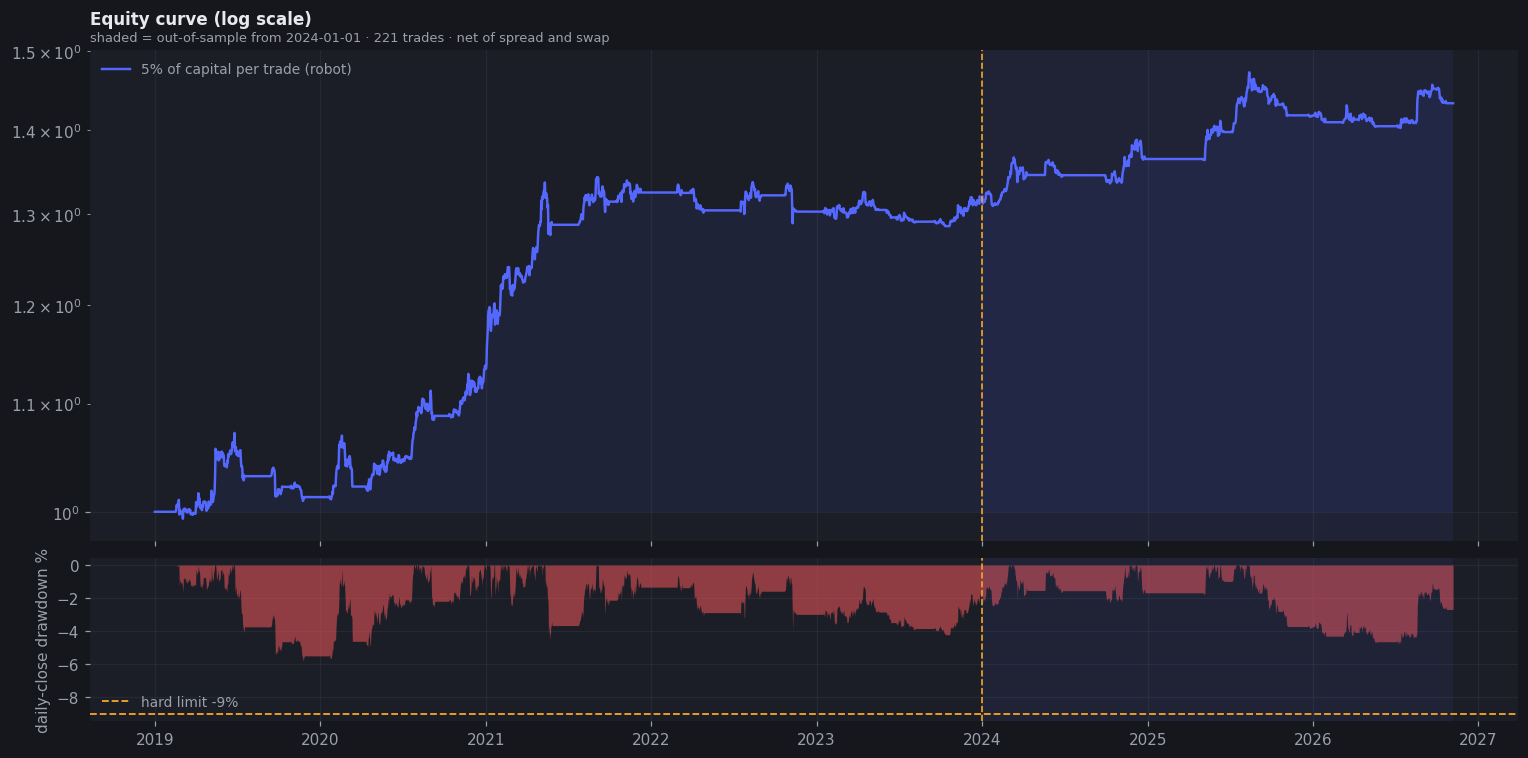


CHECKS (2):
   [PASS] N OOS >= 30  ->  72 trades
   [PASS] PF net OOS >= 1.3  ->  1.646
   [FAIL] t net OOS (overlap-adjusted) >= 1.645  ->  1.39 (plain 1.49, one-sided 5 %)
   [PASS] hard limit at the ideal fraction (full period)  ->  max DD -6.55% vs -9%
   [PASS] hard limit lot-adjusted at capital 3,500  ->  max DD -8.80% | headroom +0.20 pts


'PASS'

In [3]:
df_raw = eng.load_data(TICKER, start=DATA_START)
preps = {L: eng.prepare(df_raw, lookback_days=L, entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR) for L in LOOKBACKS}
df = preps[LOOKBACK]

n_is = int((df.index < OOS_START).sum())
df_is, df_oos = df.iloc[:n_is].copy(), df.iloc[n_is:].copy()
oos_start = df_oos.index[0]

trades_all = eng.run_weekly_backtest(df, **RULES)
trades_is, trades_oos = eng.split_trades(trades_all, oos_start)

def sized(t, sizing):
    return t if sizing == "capital" else t.assign(pnl=t["pnl_frac"], win=t["pnl_frac"] > 0)

def perf_row(t, d_slice, period, sizing):
    m = compute_metrics(sized(t, sizing), contract_multiplier=1.0, cost_per_trade=0.0)
    ret = eng.daily_returns(df, t, sizing=sizing)
    lo, hi = d_slice.index[0].normalize(), d_slice.index[-1]
    ret = ret[(ret.index >= lo) & (ret.index <= hi)]
    eq = (1.0 + ret).cumprod()
    yrs = (hi - d_slice.index[0]).days / 365.25
    return {"Period": period, "Sizing": "100% Capital" if sizing == "capital" else f"{SIZE_FRAC:.0%} Capital (robot)",
            "Trades": m["num_trades"], "Win Rate": f"{m['win_rate']:.1f}%", "Profit Factor": f"{m['profit_factor']:.3f}",
            "Expectancy": f"{m['expectancy']:.3f}%", "Total Return": f"{(eq.iloc[-1] - 1) * 100:.1f}%",
            "CAGR": f"{((eq.iloc[-1] ** (1 / yrs)) - 1) * 100:.1f}%" if yrs > 0 else "n/a",
            "Sharpe": f"{sharpe_ratio(ret, periods_per_year=PPY):.2f}", "Max Drawdown": f"{max_drawdown(eq) * 100:.2f}%"}

periods = [(f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", trades_is, df_is),
           (f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", trades_oos, df_oos),
           (f"Full Period ({df.index[0].year}-{df.index[-1].year})", trades_all, df)]
perf_table = pd.DataFrame([perf_row(t, d, name, s) for name, t, d in periods for s in ("capital", "fraction")])
print("=" * 80); print("OOS PERFORMANCE & COMPARISON (NET OF SPREAD AND SWAP)"); print("=" * 80)
display(perf_table)

m_is, m_oos = compute_metrics(trades_is, 1.0, 0.0), compute_metrics(trades_oos, 1.0, 0.0)
pnl_oos = trades_oos["pnl"].to_numpy(float)
pf_oos_nb = profit_factor(np.delete(pnl_oos, pnl_oos.argmax())) if len(pnl_oos) > 1 else np.nan
t_is_, t_oos_ = tstat(trades_is["pnl"]), tstat(pnl_oos)
print(f"PF IS {m_is['profit_factor']:.3f} -> OOS {m_oos['profit_factor']:.3f} | OOS without best trade {pf_oos_nb:.3f} | "
      f"t-stat of the mean: IS {t_is_:.2f} / OOS {t_oos_:.2f} | OOS trades {len(trades_oos)}")

# ---- Hard limit (intra-candle) at the robot's fraction and lot-adjusted at CAPITAL ----
lot = eng.cfd_trade_sizes(trades_all, CAPITAL, SIZE_FRAC)
hl_rows = []
for name, t in (("Full, ideal fraction", trades_all), ("OOS, ideal fraction", trades_oos)):
    r = eng.hard_limit_report_intrabar(df, t, HARD_LIMIT, "fraction")
    hl_rows.append({"Case": name, "Max DD intra-candle %": r["max_dd"] * 100, "Max DD closes %": r["max_dd_close"] * 100, "Headroom pts": r["headroom"] * 100, "Hard limit": "PASS" if r["passed"] else "FAIL"})
r_lot = eng.hard_limit_report_intrabar(df, trades_all, HARD_LIMIT, lot["size_fraction"].to_numpy())
hl_rows.append({"Case": f"Full, lot-adjusted (capital {CAPITAL:,.0f})", "Max DD intra-candle %": r_lot["max_dd"] * 100, "Max DD closes %": r_lot["max_dd_close"] * 100,
                "Headroom pts": r_lot["headroom"] * 100, "Hard limit": "PASS" if r_lot["passed"] else "FAIL"})
hl_tbl = pd.DataFrame(hl_rows).set_index("Case")
print(f"\nHARD LIMIT -{HARD_LIMIT:.0%}"); display(hl_tbl.round(2))

EFF_FRAC = float(lot["size_fraction"].mean())
print(f"Lot-adjusted size at capital {CAPITAL:,.0f}: mean {EFF_FRAC:.1%} of equity per trade (ideal {SIZE_FRAC:.0%}) | trades forced to the minimum lot: {int(lot['forced_min_lot'].sum())} of {len(lot)}")

t_is_h, t_oos_h = tstat_hac(trades_is["pnl"], LAGS), tstat_hac(pnl_oos, LAGS)
t_full_h = tstat_hac(trades_all["pnl"], LAGS)
print(f"Overlap-adjusted t (Newey-West, lag {LAGS}): IS {t_is_h:.2f} | OOS {t_oos_h:.2f} | full {t_full_h:.2f}   (plain t above treats overlapping trades as independent)")

ret_fr = eng.daily_returns(df, trades_all, sizing="fraction")
eq = (1 + ret_fr).cumprod()
fig, (ax1, ax2) = subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax1.plot(eq.index, eq, color=BLUE, lw=1.6, label=f"{SIZE_FRAC:.0%} of capital per trade (robot)")
ax1.fill_between(eq.index, 1, eq, where=eq >= 1, color=BLUE, alpha=0.08, lw=0)
ax2.fill_between(ret_fr.index, 100 * drawdown(ret_fr), 0, color=RED, alpha=0.55, lw=0)
ax2.axhline(-100 * HARD_LIMIT, color=ORANGE, ls="--", lw=1.2, label=f"hard limit -{HARD_LIMIT:.0%}")
for ax in (ax1, ax2):
    ax.axvspan(oos_start, ret_fr.index[-1], color=BLUE, alpha=0.07, lw=0); ax.axvline(oos_start, color=ORANGE, ls="--", lw=1.1)
ax1.set_yscale("log"); ax2.set_ylabel("daily-close drawdown %")
set_title(ax1, "Equity curve (log scale)", f"shaded = out-of-sample from {oos_start:%Y-%m-%d} · {len(trades_all)} trades · net of spread and swap")
legend(ax1); legend(ax2, "lower left"); plt.tight_layout(); plt.show()

print("\nCHECKS (2):")
check("2 OOS", f"N OOS >= {N_OOS_MIN}", len(trades_oos) >= N_OOS_MIN, f"{len(trades_oos)} trades")
check("2 OOS", f"PF net OOS >= {PF_MIN}", m_oos["profit_factor"] >= PF_MIN, f"{m_oos['profit_factor']:.3f}")
check("2 OOS", f"t net OOS (overlap-adjusted) >= {T_ONE_SIDED:.3f}", t_oos_h >= T_ONE_SIDED, f"{t_oos_h:.2f} (plain {t_oos_:.2f}, one-sided 5 %)")
check("2 OOS", "hard limit at the ideal fraction (full period)", hl_tbl.iloc[0]["Hard limit"] == "PASS", f"max DD {hl_tbl.iloc[0]['Max DD intra-candle %']:.2f}% vs -{HARD_LIMIT:.0%}")
check("2 OOS", f"hard limit lot-adjusted at capital {CAPITAL:,.0f}", hl_tbl.iloc[2]["Hard limit"] == "PASS",
      f"max DD {hl_tbl.iloc[2]['Max DD intra-candle %']:.2f}% | headroom {hl_tbl.iloc[2]['Headroom pts']:+.2f} pts")

## 3. WALK-FORWARD ANALYSIS (FIXED RULES: 3Y IS / 1Y OOS)

No refitting: each calendar year is compared with the annualised return of the three full years before it (the window shortens 3 → 2 → 1 until there are at least two windows).

Walk-forward IS window: 3 year(s)
WALK-FORWARD SUMMARY (4 ROLLING WINDOWS, 5% sizing)
Walk-Forward Efficiency (OOS mean / IS annual mean): 0.549 (>= 0.50)
Positive OOS years ratio: 100.0% (4/4) (>= 60%)
Worst single-year OOS drawdown: -3.84% (> -20%)
Walk-Forward Gate Verdict: PASSED


,year,ret_is_anual,ret_oos,mdd_oos,n_oos
0,2023,0.0874,0.0103,-0.0298,36
1,2024,0.0506,0.0367,-0.0226,26
2,2025,0.0099,0.0388,-0.0384,21
3,2026,0.0285,0.0111,-0.0198,25


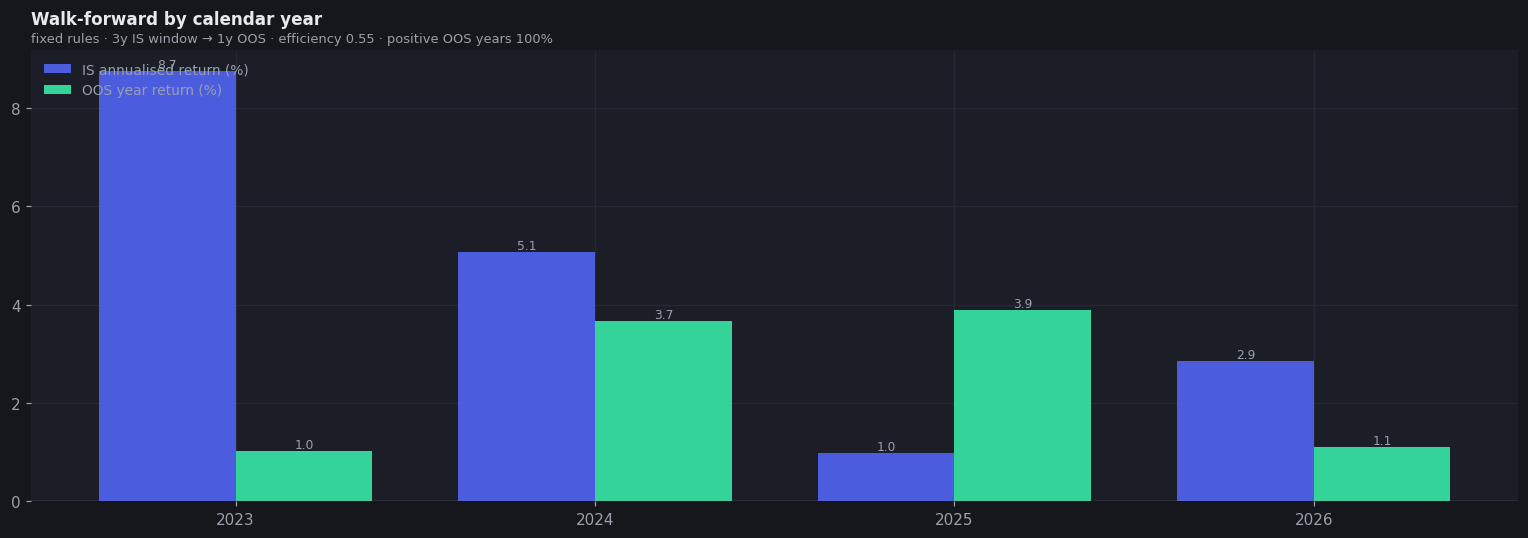


CHECKS (3):
   [PASS] efficiency >= 0.5  ->  0.55
   [PASS] positive OOS years >= 60%  ->  100% (4/4)
   [PASS] worst-year OOS drawdown inside -20% (gate)  ->  -3.84%
   [PASS] worst-year OOS drawdown inside the hard limit (-9%)  ->  -3.84%


'PASS'

In [4]:
for _y in (3, 2, 1):
    wf_df = eng.walk_forward_fixed(df, rules=RULES, is_years=_y, sizing="fraction")
    WF_IS_YEARS = _y
    if len(wf_df) >= 2:
        break
assert len(wf_df) > 0, "No walk-forward windows: need at least one full year before the first tested year."
print(f"Walk-forward IS window: {WF_IS_YEARS} year(s)" + ("" if WF_IS_YEARS == 3 else "  (shortened from 3: not enough full years)"))

mean_is, mean_oos = wf_df["ret_is_anual"].mean(), wf_df["ret_oos"].mean()
efficiency = mean_oos / mean_is if mean_is > 0 else np.nan
pct_positive_years = float((wf_df["ret_oos"] > 0).mean())
worst_oos_mdd = float(wf_df["mdd_oos"].min())
wf_pass = bool(np.isfinite(efficiency) and efficiency >= 0.5 and pct_positive_years >= 0.60 and worst_oos_mdd > -0.20)

print("=" * 70); print(f"WALK-FORWARD SUMMARY ({len(wf_df)} ROLLING WINDOWS, {SIZE_FRAC:.0%} sizing)"); print("=" * 70)
print(f"Walk-Forward Efficiency (OOS mean / IS annual mean): {efficiency:.3f} (>= 0.50)")
print(f"Positive OOS years ratio: {pct_positive_years * 100:.1f}% ({int((wf_df['ret_oos'] > 0).sum())}/{len(wf_df)}) (>= 60%)")
print(f"Worst single-year OOS drawdown: {worst_oos_mdd * 100:.2f}% (> -20%)")
print(f"Walk-Forward Gate Verdict: {'PASSED' if wf_pass else 'FAILED'}")
display(wf_df.round(4))

fig, ax = subplots(figsize=(14, 5))
x, w = np.arange(len(wf_df)), 0.38
b1 = ax.bar(x - w / 2, wf_df["ret_is_anual"] * 100, w, color=BLUE, alpha=0.85, label="IS annualised return (%)")
b2 = ax.bar(x + w / 2, wf_df["ret_oos"] * 100, w, color=[GREEN if r > 0 else RED for r in wf_df["ret_oos"]], label="OOS year return (%)")
for rect in list(b1) + list(b2):
    h = rect.get_height()
    ax.text(rect.get_x() + rect.get_width() / 2, h, f"{h:.1f}", ha="center", va="bottom" if h >= 0 else "top", fontsize=8, color=SUB)
ax.axhline(0, color=SUB, lw=0.8); ax.set_xticks(x); ax.set_xticklabels(wf_df["year"])
set_title(ax, "Walk-forward by calendar year", f"fixed rules · {WF_IS_YEARS}y IS window → 1y OOS · efficiency {efficiency:.2f} · positive OOS years {pct_positive_years:.0%}")
legend(ax); plt.tight_layout(); plt.show()

print("\nCHECKS (3):")
check("3 Walk-forward", "efficiency >= 0.5", bool(np.isfinite(efficiency) and efficiency >= 0.5), f"{efficiency:.2f}")
check("3 Walk-forward", "positive OOS years >= 60%", pct_positive_years >= 0.60, f"{pct_positive_years:.0%} ({int((wf_df['ret_oos'] > 0).sum())}/{len(wf_df)})")
check("3 Walk-forward", "worst-year OOS drawdown inside -20% (gate)", worst_oos_mdd > -0.20, f"{worst_oos_mdd * 100:.2f}%")
check("3 Walk-forward", f"worst-year OOS drawdown inside the hard limit (-{HARD_LIMIT:.0%})", worst_oos_mdd >= -HARD_LIMIT, f"{worst_oos_mdd * 100:.2f}%")

## 4. BLOCK MONTE CARLO BOOTSTRAP (10,000 SIMULATIONS)

Circular block resampling of the hourly MTM paths, at the robot's size, at 2x, and at the **real lot-adjusted size** of `CAPITAL`. The worst-5 % drawdown is compared with the account's hard limit.

BLOCK MONTE CARLO SUMMARY (10,000 RUNS, hourly-MTM drawdown)


,Median return,p5 return,Median max DD,Worst-5% DD (mdd_p5),Worst simulated DD,Prob. ruin (50% DD),Prob. positive,Real DD of this history
Sizing,,,,,,,,
5% (robot),42.9%,16.9%,-6.15%,-9.89%,-17.89%,0.00%,99.8%,-5.93%
10% (2x robot),101.8%,35.3%,-11.99%,-18.98%,-32.84%,0.00%,99.8%,-11.53%
"5.5% (lot-adjusted, capital 3,500)",31.1%,6.6%,-8.22%,-13.53%,-24.97%,0.00%,98.4%,-7.63%


Gate limit on mdd_p5: -25% | hard limit of the account: -9%


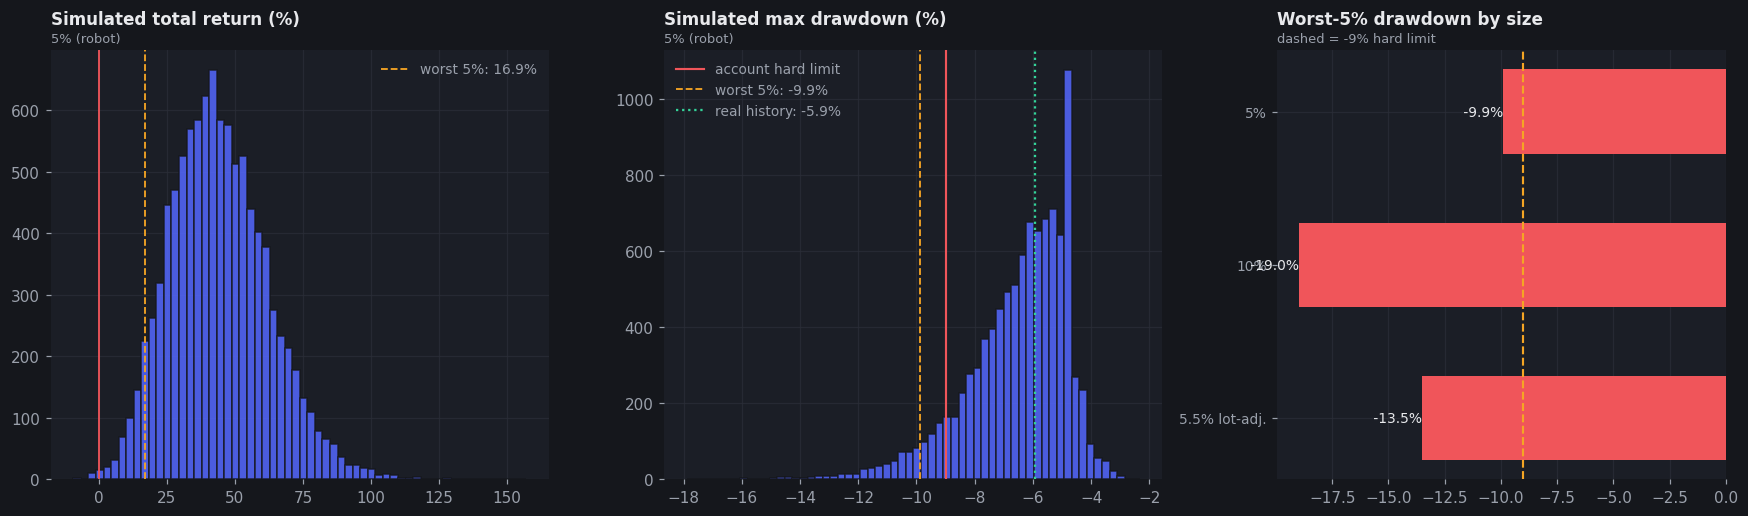


CHECKS (4):
   [PASS] worst-5% DD inside the gate limit (-25%)  ->  -9.89% at 5% (robot)
   [FAIL] worst-5% DD inside the hard limit (-9%) at the robot size  ->  -9.89%
   [FAIL] worst-5% DD inside the hard limit at the real lot-adjusted size (capital 3,500)  ->  -13.53% at 5.5% per trade
   [PASS] p5 of total return > 0 (robot size)  ->  16.9%
   [PASS] probability of ruin (50% DD) <= 1% (robot size)  ->  0.00%


'PASS'

In [5]:
lot_fr = lot["size_fraction"].to_numpy()
paths = {k: eng.trade_mtm_paths(df, trades_all, sizing=f) for k, f in SIZES.items()}
mcs = {k: monte_carlo_block(scaled(trades_all, f), n_sim=10000, block=5, mode="compound", seed=42, mtm_paths=paths[k]) for k, f in SIZES.items()}
LOT_KEY = f"{EFF_FRAC:.1%} (lot-adjusted, capital {CAPITAL:,.0f})"
mcs_all = {**mcs, LOT_KEY: monte_carlo_block(scaled(trades_all, lot_fr), n_sim=10000, block=5, mode="compound", seed=42,
                                             mtm_paths=eng.trade_mtm_paths(df, trades_all, sizing=lot_fr))}

rows = []
for k, m in mcs_all.items():
    rows.append({"Sizing": k, "Median return": f"{m['ret_p50'] * 100:.1f}%", "p5 return": f"{m['ret_p5'] * 100:.1f}%",
                 "Median max DD": f"{m['mdd_p50'] * 100:.2f}%", "Worst-5% DD (mdd_p5)": f"{m['mdd_p5'] * 100:.2f}%",
                 "Worst simulated DD": f"{m['mdd_worst'] * 100:.2f}%", "Prob. ruin (50% DD)": f"{m['prob_ruin'] * 100:.2f}%",
                 "Prob. positive": f"{m['prob_positive'] * 100:.1f}%", "Real DD of this history": f"{m['real_mdd'] * 100:.2f}%"})
print("=" * 70); print("BLOCK MONTE CARLO SUMMARY (10,000 RUNS, hourly-MTM drawdown)"); print("=" * 70)
display(pd.DataFrame(rows).set_index("Sizing"))
print(f"Gate limit on mdd_p5: {GATE['mc_mdd_p5_min'] * 100:.0f}% | hard limit of the account: -{HARD_LIMIT:.0%}")

mc0, mc_lot = mcs[OFFICIAL], mcs_all[LOT_KEY]
fig, (ax1, ax2, ax3) = subplots(1, 3, figsize=(16, 4.8), gridspec_kw=dict(width_ratios=[1, 1, 0.9]))
ax1.hist(mc0["rets"] * 100, bins=60, color=BLUE, alpha=0.85, edgecolor=BG)
ax1.axvline(0, color=RED, lw=1.2); ax1.axvline(mc0["ret_p5"] * 100, color=ORANGE, ls="--", lw=1.2, label=f"worst 5%: {mc0['ret_p5'] * 100:.1f}%")
set_title(ax1, "Simulated total return (%)", OFFICIAL); legend(ax1, "upper right")
ax2.hist(mc0["mdds"] * 100, bins=60, color=BLUE, alpha=0.85, edgecolor=BG)
ax2.axvline(-HARD_LIMIT * 100, color=RED, lw=1.4, label="account hard limit"); ax2.axvline(mc0["mdd_p5"] * 100, color=ORANGE, ls="--", lw=1.2, label=f"worst 5%: {mc0['mdd_p5'] * 100:.1f}%")
ax2.axvline(mc0["real_mdd"] * 100, color=GREEN, ls=":", lw=1.5, label=f"real history: {mc0['real_mdd'] * 100:.1f}%")
set_title(ax2, "Simulated max drawdown (%)", OFFICIAL); legend(ax2, "upper left")
names, vals = list(mcs_all), [m["mdd_p5"] * 100 for m in mcs_all.values()]
ax3.barh(range(len(vals)), vals, color=[GREEN if v >= -HARD_LIMIT * 100 else RED for v in vals], height=0.55)
ax3.axvline(-HARD_LIMIT * 100, color=ORANGE, ls="--", lw=1.4)
ax3.set_yticks(range(len(vals))); ax3.set_yticklabels([n.split(" (")[0] + (" lot-adj." if "lot-adjusted" in n else "") for n in names], fontsize=9)
for i, v in enumerate(vals):
    ax3.text(v, i, f" {v:.1f}%", va="center", ha="right", fontsize=9, color=TXT)
set_title(ax3, "Worst-5% drawdown by size", f"dashed = -{HARD_LIMIT:.0%} hard limit"); ax3.invert_yaxis()
plt.tight_layout(); plt.show()

print("\nCHECKS (4):")
check("4 Monte Carlo", f"worst-5% DD inside the gate limit ({GATE['mc_mdd_p5_min'] * 100:.0f}%)", mc0["mdd_p5"] > GATE["mc_mdd_p5_min"], f"{mc0['mdd_p5'] * 100:.2f}% at {OFFICIAL}")
check("4 Monte Carlo", f"worst-5% DD inside the hard limit (-{HARD_LIMIT:.0%}) at the robot size", mc0["mdd_p5"] > -HARD_LIMIT, f"{mc0['mdd_p5'] * 100:.2f}%")
check("4 Monte Carlo", f"worst-5% DD inside the hard limit at the real lot-adjusted size (capital {CAPITAL:,.0f})", mc_lot["mdd_p5"] > -HARD_LIMIT,
      f"{mc_lot['mdd_p5'] * 100:.2f}% at {EFF_FRAC:.1%} per trade")
check("4 Monte Carlo", "p5 of total return > 0 (robot size)", mc0["ret_p5"] > 0, f"{mc0['ret_p5'] * 100:.1f}%")
check("4 Monte Carlo", "probability of ruin (50% DD) <= 1% (robot size)", mc0["prob_ruin"] <= 0.01, f"{mc0['prob_ruin'] * 100:.2f}%")

## 5. MONKEY TEST (2,000 SYNTHETIC RANDOM PORTFOLIOS) AND MULTIPLE-TESTING BAR

Written here (not in the gate) so spread and swap are charged exactly like the engine does. **A** asks whether the *timing* matters (random entries at any hour); **B** whether momentum picks better weeks than chance among the signal weeks, with the trial-corrected level `1 - 0.05 / N_TRIALS`.

MONKEY TEST RESULTS
A · timing monkey (any hour): strategy PF 1.886 | monkey median PF 1.275 | beats 98.4% on PF, 98.5% on expectancy (gate >= 95%)
B · signal monkey (random signal weeks): strategy PF 1.886 | monkey median PF 1.291 | beats 99.9% on PF, 100.0% on expectancy (gate >= 95%)
B with the trial-corrected level (2 trials): need >= 97.5% -> PASS


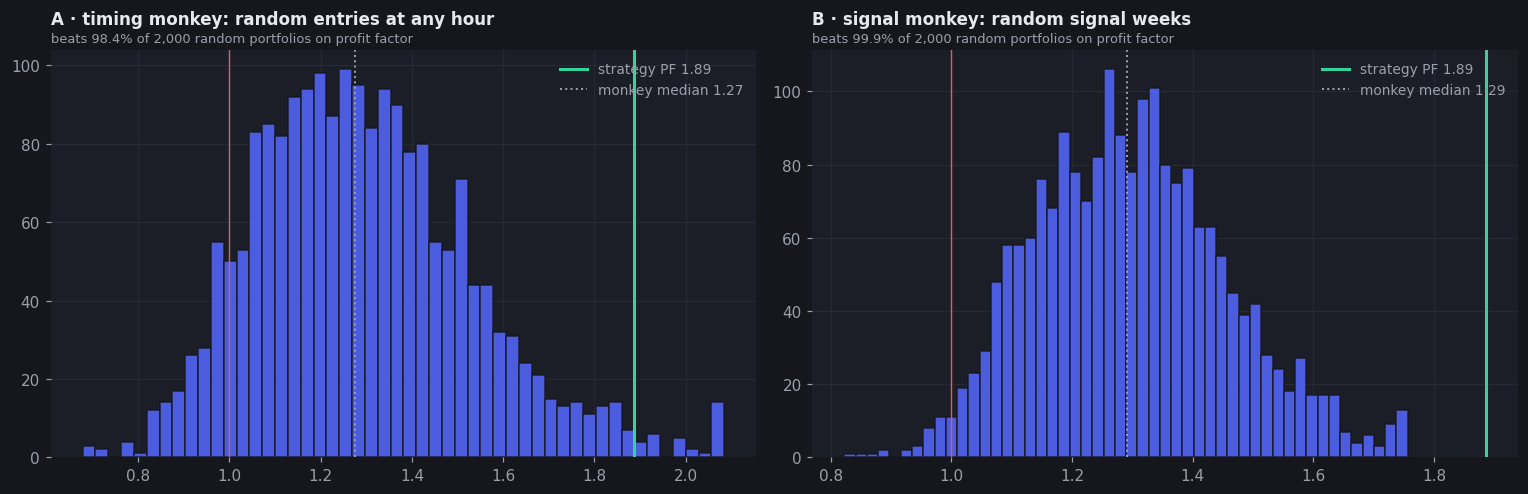


CHECKS (5 monkey):
   [PASS] A · timing monkey: beats >= 95% on PF  ->  98.4%
   [PASS] B · signal monkey: beats >= 97.5% on PF (2 trials)  ->  99.9%


'PASS'

In [6]:
rng = np.random.default_rng(42)
N_SIM = 2000
n_tr = len(trades_all)
p_long = float((trades_all["side"] > 0).mean())

def pf_exp(M):
    g = np.where(M > 0, M, 0.0).sum(axis=1); l = -np.where(M < 0, M, 0.0).sum(axis=1)
    return np.where(l > 0, g / np.maximum(l, 1e-12), np.inf), M.mean(axis=1)

real_pf, real_exp = profit_factor(trades_all["pnl"]), float(trades_all["pnl"].mean())

# ---- A: every hourly bar is a possible entry; net pnl of a long / a short held HOLD days (spread of the correct candle + swap) ----
o, sp = df["open"].to_numpy(float), df["spread_px"].to_numpy(float)
idx = df.index.values
j = np.searchsorted(idx, idx + np.timedelta64(HOLD, "D"))
ok = (j < len(idx)); ok[ok] &= idx[j[ok]] == idx[ok] + np.timedelta64(HOLD, "D")
ii, jj = np.flatnonzero(ok), j[ok]
long_c  = ((o[jj] / (o[ii] + sp[ii]) - 1.0) * 100.0) + SWAP_L0 / 365.0 * HOLD
short_c = ((o[ii] - (o[jj] + sp[jj])) / o[ii] * 100.0) + SWAP_S0 / 365.0 * HOLD
pick = rng.integers(0, len(ii), (N_SIM, n_tr))
if DIRECTION == "long_only":    A = long_c[pick]
elif DIRECTION == "short_only": A = short_c[pick]
else:                           A = np.where(rng.random((N_SIM, n_tr)) < p_long, long_c[pick], short_c[pick])

# ---- B: only signal weeks (every Monday with a valid signal), same leg(s) as the rule ----
sig = eng.run_weekly_backtest(df, **{**RULES, "direction": "both"})
def naked_pnl(direction):
    d = df.copy(); d["mom_ret"] = np.abs(d["mom_ret"]) * (1.0 if direction == "long_only" else -1.0)
    t = eng.run_weekly_backtest(d, **{**RULES, "direction": direction})
    return sig["i_ent"].map(t.set_index("i_ent")["pnl"]).to_numpy(float)
wk_long, wk_short = naked_pnl("long_only"), naked_pnl("short_only")
good = np.isfinite(wk_long) & np.isfinite(wk_short)
wk_long, wk_short = wk_long[good], wk_short[good]
sel = np.argsort(rng.random((N_SIM, len(wk_long))), axis=1)[:, :min(n_tr, len(wk_long))]
if DIRECTION == "long_only":    B = wk_long[sel]
elif DIRECTION == "short_only": B = wk_short[sel]
else:                           B = np.where(rng.random(sel.shape) < p_long, wk_long[sel], wk_short[sel])

def mk_summary(M):
    pf, ex = pf_exp(M)
    return dict(pf_real=real_pf, pf_monkey_median=float(np.median(pf)), pct_pf=float((real_pf > pf).mean()),
                pct_expectancy=float((real_exp > ex).mean()), pf=pf, ex=ex)
mk_A, mk_B = mk_summary(A), mk_summary(B)
B_LEVEL = 1 - 0.05 / N_TRIALS

print("=" * 70); print("MONKEY TEST RESULTS"); print("=" * 70)
for name, mk in (("A · timing monkey (any hour)", mk_A), ("B · signal monkey (random signal weeks)", mk_B)):
    print(f"{name}: strategy PF {mk['pf_real']:.3f} | monkey median PF {mk['pf_monkey_median']:.3f} | "
          f"beats {mk['pct_pf'] * 100:.1f}% on PF, {mk['pct_expectancy'] * 100:.1f}% on expectancy (gate >= {GATE['monkey_pct_min'] * 100:.0f}%)")
print(f"B with the trial-corrected level ({N_TRIALS} trials): need >= {B_LEVEL * 100:.1f}% -> {'PASS' if mk_B['pct_pf'] >= B_LEVEL else 'FAIL'}")

fig, axs = subplots(1, 2, figsize=(14, 4.6))
for ax, (nm, m_) in zip(axs, (("A · timing monkey: random entries at any hour", mk_A), ("B · signal monkey: random signal weeks", mk_B))):
    v = m_["pf"][np.isfinite(m_["pf"])]
    ax.hist(np.clip(v, 0, np.percentile(v, 99.5)), bins=50, color=BLUE, alpha=0.85, edgecolor=BG)
    ax.axvline(real_pf, color=GREEN, lw=2, label=f"strategy PF {real_pf:.2f}")
    ax.axvline(float(np.median(v)), color=SUB, ls=":", lw=1.3, label=f"monkey median {np.median(v):.2f}"); ax.axvline(1.0, color=RED, lw=0.9)
    set_title(ax, nm, f"beats {m_['pct_pf'] * 100:.1f}% of {N_SIM:,} random portfolios on profit factor"); legend(ax, "upper right")
plt.tight_layout(); plt.show()

print("\nCHECKS (5 monkey):")
check("5 Monkey", f"A · timing monkey: beats >= {GATE['monkey_pct_min'] * 100:.0f}% on PF", mk_A["pct_pf"] >= GATE["monkey_pct_min"], f"{mk_A['pct_pf'] * 100:.1f}%")
check("5 Monkey", f"B · signal monkey: beats >= {B_LEVEL * 100:.1f}% on PF ({N_TRIALS} trials)", mk_B["pct_pf"] >= B_LEVEL, f"{mk_B['pct_pf'] * 100:.1f}%")

MULTIPLE-TESTING BAR · overlap-adjusted t (Newey-West, lag 1) vs one-sided Bonferroni at alpha = 0.05


,k,t bar,IS t,OOS t,Full t,Full clears
Family,,,,,,
single hypothesis,1,1.64,2.54,1.39,2.89,YES
YAML hypotheses_tested (2),2,1.96,2.54,1.39,2.89,YES
whole grid (810 cells),810,3.84,2.54,1.39,2.89,no


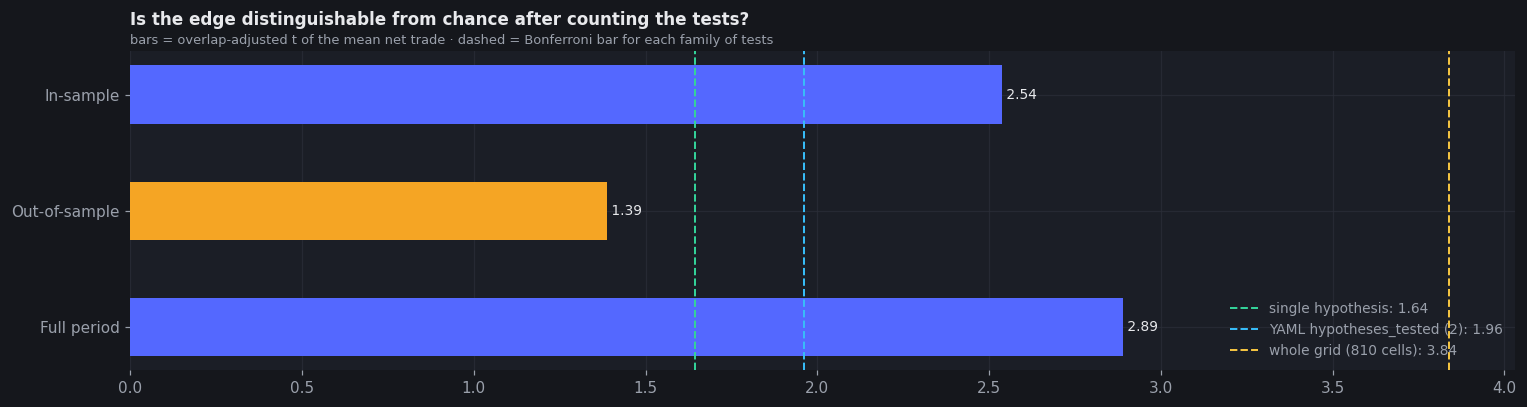


CHECKS (5 evidence):
   [PASS] full-period t >= Bonferroni bar for 2 hypotheses  ->  2.89 vs 1.96
   [INFO] bar if the whole grid (810 cells) counts as the family  ->  full t 2.89 vs 3.84 -> does not clear


'INFO'

In [7]:
# ---- multiple-testing bar: t needed for a Bonferroni-corrected one-sided test (overlap-adjusted t) ----
fam = [("single hypothesis", 1), (f"trials counted ({N_TRIALS})", N_TRIALS), (f"YAML hypotheses_tested ({K_HYP})", K_HYP), (f"whole grid ({K_GRID} cells)", K_GRID)]
fam = list({k: (n, k) for n, k in fam}.values())      # drop duplicated families (e.g. YAML = trials)
ev = pd.DataFrame([{"Family": n, "k": k, "t bar": bonferroni(k), "IS t": t_is_h, "OOS t": t_oos_h, "Full t": t_full_h,
                    "Full clears": "YES" if t_full_h >= bonferroni(k) else "no"} for n, k in fam]).set_index("Family")
print("=" * 70); print(f"MULTIPLE-TESTING BAR · overlap-adjusted t (Newey-West, lag {LAGS}) vs one-sided Bonferroni at alpha = {ALPHA}"); print("=" * 70)
display(ev.round(2))

fig, ax = subplots(figsize=(14, 3.8))
for i, (lab, v) in enumerate((("IS", t_is_h), ("OOS", t_oos_h), ("Full", t_full_h))):
    ax.barh(i, v, color=BLUE if lab != "OOS" else ORANGE, height=0.5); ax.text(v, i, f" {v:.2f}", va="center", fontsize=9, color=TXT)
for (n, k), col in zip(fam, (GREEN, CYAN, GOLD, RED)):
    ax.axvline(bonferroni(k), color=col, ls="--", lw=1.3, label=f"{n}: {bonferroni(k):.2f}")
ax.set_yticks(range(3)); ax.set_yticklabels(["In-sample", "Out-of-sample", "Full period"]); ax.invert_yaxis()
set_title(ax, "Is the edge distinguishable from chance after counting the tests?", "bars = overlap-adjusted t of the mean net trade · dashed = Bonferroni bar for each family of tests")
legend(ax, "lower right"); plt.tight_layout(); plt.show()

print("\nCHECKS (5 evidence):")
check("5 Evidence", f"full-period t >= Bonferroni bar for {K_HYP} hypotheses", t_full_h >= bonferroni(K_HYP), f"{t_full_h:.2f} vs {bonferroni(K_HYP):.2f}")
check.info("5 Evidence", f"bar if the whole grid ({K_GRID} cells) counts as the family", f"full t {t_full_h:.2f} vs {bonferroni(K_GRID):.2f} -> {'clears' if t_full_h >= bonferroni(K_GRID) else 'does not clear'}")

## 6. STRESS TESTING: SPREAD, SWAP, WINDFALL EXCLUSION, REGIMES, CONCENTRATION & TAILS

The swap (-20 % annual on longs, about 0.38 % per week) is the structural cost of this edge: the sweep scales spread and swap and finds how many times today's costs the edge can bear. The tail test is an **approximation** (the rule has no stop): a stop is simulated on the 1 h closes of each trade's MTM path and filled at the stop level, so gaps through the level are not modelled.

STRESS TESTING BATTERY


,Trades,Profit Factor,Mean net %,t-stat
Scenario,,,,
Base,221,1.886,3.315,3.25
Spread x2,221,1.838,3.177,3.13
Swap x2,221,1.671,2.699,2.66
Spread x2 + Swap x2,221,1.629,2.562,2.53
Spread x3 + Swap x3,221,1.410,1.811,1.80


Per trade: gross +4.071% | spread 0.140% | swap 0.616% | net +3.315%
Break-even: spread + swap can be ~5.4x today's | swap alone ~6.4x today's (long swap -20% -> about -128% annual)



,Trades,Profit Factor,Expectancy
Stress Scenario,,,
Baseline,221,1.886,3.315%
Spread x2 + Swap x2,221,1.629,2.562%
"Exclude best years (2020, 2021)",148,1.341,1.277%
Exclude best 10% of trades (23),198,0.947,-0.222%
2018-19 (range / bear),26,1.219,1.062%
2020-21 (bull),73,2.998,7.448%
2022 (bear),14,0.648,-2.355%
2023 (recovery),36,1.392,0.942%
2024+ (OOS),72,1.646,2.227%


Best 10% of trades (23) carry 50% of gross profit.

Without bull years (2020, 2021): 148 trades | PF 1.341 | mean net +1.277% | t (Newey-West, approximate on the remaining trades) 1.13


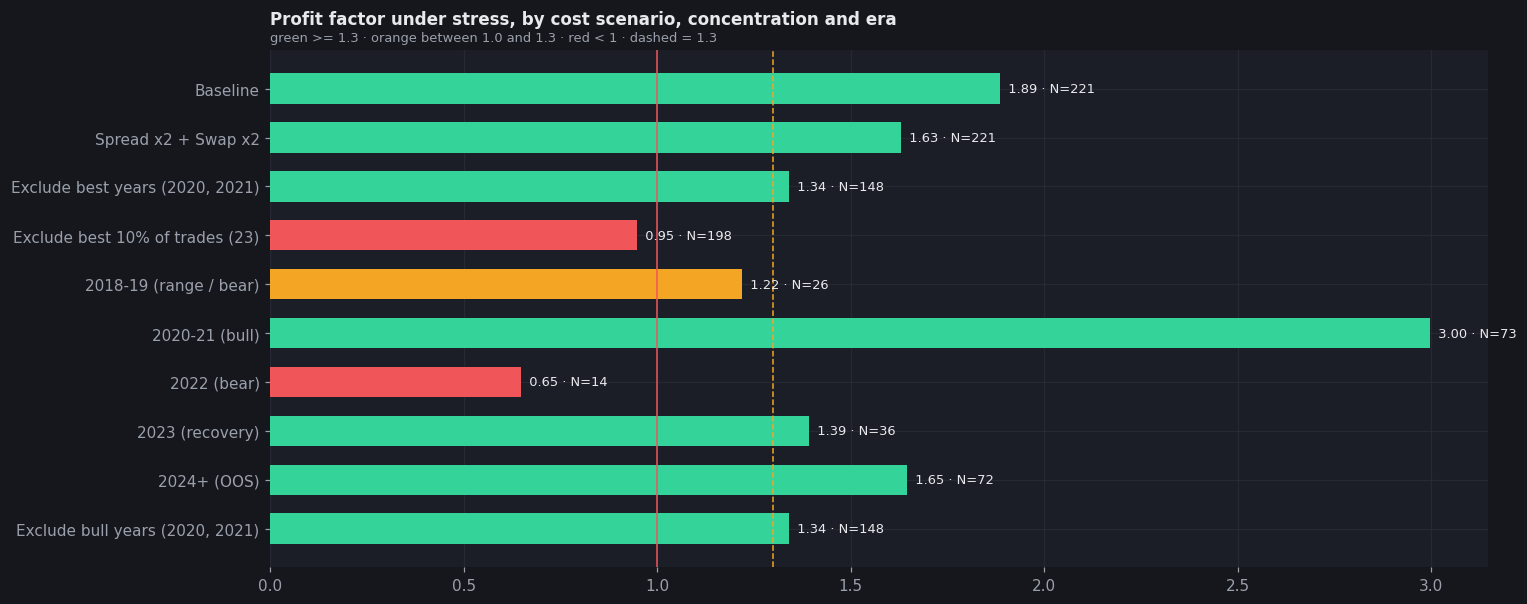


CHECKS (6):
   [PASS] spread x2 + swap x2: PF >= 1  ->  PF 1.629
   [PASS] without the best 2 years: PF >= 1  ->  PF 1.341 (excluded [2020, 2021])
   [FAIL] without the best 10% of trades: mean net >= 0  ->  -0.222% (best 10% carry 50% of gross profit)
   [PASS] without the bull years (2020, 2021): PF >= 1  ->  PF 1.341
   [PASS] cost break-even multiple >= 2x  ->  5.4x (swap alone 6.4x)


'PASS'

In [8]:
print("=" * 70); print("STRESS TESTING BATTERY"); print("=" * 70)

def run_scaled(sp_k, sw_k):
    eng.set_engine_defaults(swap_long_pct_annual=SWAP_L0 * sw_k, swap_short_pct_annual=SWAP_S0 * sw_k)
    try:
        d = df.copy(); d["spread_px"] = d["spread_px"] * sp_k
        return eng.run_weekly_backtest(d, **RULES)
    finally:
        eng.set_engine_defaults(swap_long_pct_annual=SWAP_L0, swap_short_pct_annual=SWAP_S0)

rows = []
for name, a, b in (("Base", 1, 1), ("Spread x2", 2, 1), ("Swap x2", 1, 2), ("Spread x2 + Swap x2", 2, 2), ("Spread x3 + Swap x3", 3, 3)):
    t = run_scaled(a, b); m = compute_metrics(t, 1.0, 0.0)
    rows.append({"Scenario": name, "Trades": len(t), "Profit Factor": round(m["profit_factor"], 3), "Mean net %": round(m["expectancy"], 3), "t-stat": round(tstat(t["pnl"]), 2)})
cost_tbl = pd.DataFrame(rows).set_index("Scenario")
display(cost_tbl)

gross, spread_c, swap_c = trades_all["gross_pct"].mean(), trades_all["cost_pct"].mean(), -trades_all["swap_pct"].mean()
be_all  = gross / (spread_c + swap_c) if spread_c + swap_c > 0 else np.inf
be_swap = (gross - spread_c) / swap_c if swap_c > 0 else np.inf
print(f"Per trade: gross {gross:+.3f}% | spread {spread_c:.3f}% | swap {swap_c:.3f}% | net {trades_all['pnl'].mean():+.3f}%")
print(f"Break-even: spread + swap can be ~{be_all:.1f}x today's | swap alone ~{be_swap:.1f}x today's (long swap {SWAP_L0:g}% -> about {SWAP_L0 * be_swap:.0f}% annual)")

trades_all["year"] = pd.to_datetime(trades_all["entry_time"]).dt.year
annual = trades_all.groupby("year")["pnl"].sum()
top2 = annual.sort_values(ascending=False).head(2).index.tolist()
t_ex = trades_all[~trades_all["year"].isin(top2)]
m_ex, m_base = compute_metrics(t_ex, 1.0, 0.0), compute_metrics(trades_all, 1.0, 0.0)
k = max(1, int(np.ceil(0.10 * len(trades_all))))
srt = trades_all["pnl"].sort_values(ascending=False)
share_top10 = float(srt.head(k).sum() / trades_all["pnl"].clip(lower=0).sum())
pf_ex_top10 = profit_factor(srt.iloc[k:].to_numpy())

stress_rows = [
    {"Stress Scenario": "Baseline", "Trades": len(trades_all), "Profit Factor": f"{m_base['profit_factor']:.3f}", "Expectancy": f"{m_base['expectancy']:.3f}%"},
    {"Stress Scenario": "Spread x2 + Swap x2", "Trades": int(cost_tbl.loc["Spread x2 + Swap x2", "Trades"]), "Profit Factor": f"{cost_tbl.loc['Spread x2 + Swap x2', 'Profit Factor']:.3f}", "Expectancy": f"{cost_tbl.loc['Spread x2 + Swap x2', 'Mean net %']:.3f}%"},
    {"Stress Scenario": f"Exclude best years ({top2[0]}, {top2[1]})", "Trades": len(t_ex), "Profit Factor": f"{m_ex['profit_factor']:.3f}", "Expectancy": f"{m_ex['expectancy']:.3f}%"},
    {"Stress Scenario": f"Exclude best 10% of trades ({k})", "Trades": len(trades_all) - k, "Profit Factor": f"{pf_ex_top10:.3f}", "Expectancy": f"{srt.iloc[k:].mean():.3f}%"},
]
for name, (a, b) in ERAS.items():
    tr = trades_all[(trades_all["year"] >= a) & (trades_all["year"] <= b)]
    if len(tr):
        mr = compute_metrics(tr, 1.0, 0.0)
        stress_rows.append({"Stress Scenario": name, "Trades": len(tr), "Profit Factor": f"{mr['profit_factor']:.3f}", "Expectancy": f"{mr['expectancy']:.3f}%"})
print(); display(pd.DataFrame(stress_rows).set_index("Stress Scenario"))
print(f"Best 10% of trades ({k}) carry {share_top10 * 100:.0f}% of gross profit.")
x2 = cost_tbl.loc["Spread x2 + Swap x2"]
stress_ok = bool(x2["Profit Factor"] >= 1.0 and m_ex["profit_factor"] >= 1.0)

# ---- bull years removed (declared a priori in notebook 01) ----
no_bull = trades_all[~trades_all["year"].isin(BULL_YEARS)]
pf_nb = profit_factor(no_bull["pnl"])
print(f"\nWithout bull years {BULL_YEARS}: {len(no_bull)} trades | PF {pf_nb:.3f} | mean net {no_bull['pnl'].mean():+.3f}% | t (Newey-West, approximate on the remaining trades) {tstat_hac(no_bull['pnl'], LAGS):.2f}")

sr = pd.DataFrame(stress_rows)
sr["PF"] = sr["Profit Factor"].astype(float)
sr = pd.concat([sr, pd.DataFrame([{"Stress Scenario": f"Exclude bull years {BULL_YEARS}", "Trades": len(no_bull), "PF": pf_nb}])], ignore_index=True)
fig, ax = subplots(figsize=(14, 5.6))
yy = np.arange(len(sr))[::-1]
ax.barh(yy, sr["PF"], color=[GREEN if v >= PF_MIN else (ORANGE if v >= 1 else RED) for v in sr["PF"]], height=0.62)
ax.axvline(1.0, color=RED, lw=1); ax.axvline(PF_MIN, color=ORANGE, ls="--", lw=1)
ax.set_yticks(yy); ax.set_yticklabels(sr["Stress Scenario"])
for y_, v_, n_ in zip(yy, sr["PF"], sr["Trades"]):
    ax.text(v_, y_, f"  {v_:.2f} · N={int(n_)}", va="center", fontsize=8.5, color=TXT)
set_title(ax, "Profit factor under stress, by cost scenario, concentration and era", f"green >= {PF_MIN} · orange between 1.0 and {PF_MIN} · red < 1 · dashed = {PF_MIN}")
plt.tight_layout(); plt.show()

print("\nCHECKS (6):")
check("6 Stress", "spread x2 + swap x2: PF >= 1", float(x2["Profit Factor"]) >= 1.0, f"PF {float(x2['Profit Factor']):.3f}")
check("6 Stress", "without the best 2 years: PF >= 1", m_ex["profit_factor"] >= 1.0, f"PF {m_ex['profit_factor']:.3f} (excluded {top2})")
check("6 Stress", "without the best 10% of trades: mean net >= 0", float(srt.iloc[k:].mean()) >= 0, f"{srt.iloc[k:].mean():+.3f}% (best 10% carry {share_top10 * 100:.0f}% of gross profit)")
check("6 Stress", f"without the bull years {BULL_YEARS}: PF >= 1", pf_nb >= 1.0, f"PF {pf_nb:.3f}")
check("6 Stress", f"cost break-even multiple >= {BE_MIN:g}x", be_all >= BE_MIN, f"{be_all:.1f}x (swap alone {be_swap:.1f}x)")

APPROXIMATE STOP TEST (the rule has no stop; informational)


,Mean net %,PF,Worst trade %,Stopped trades,t-stat
Stop %,,,,,
none,3.315,1.886,-39.947,0,3.253
10,3.642,2.095,-10.000,60,3.817
15,3.406,1.940,-15.000,31,3.440
20,3.271,1.864,-20.000,17,3.228
25,3.300,1.879,-25.000,9,3.246
30,3.203,1.831,-30.000,7,3.105


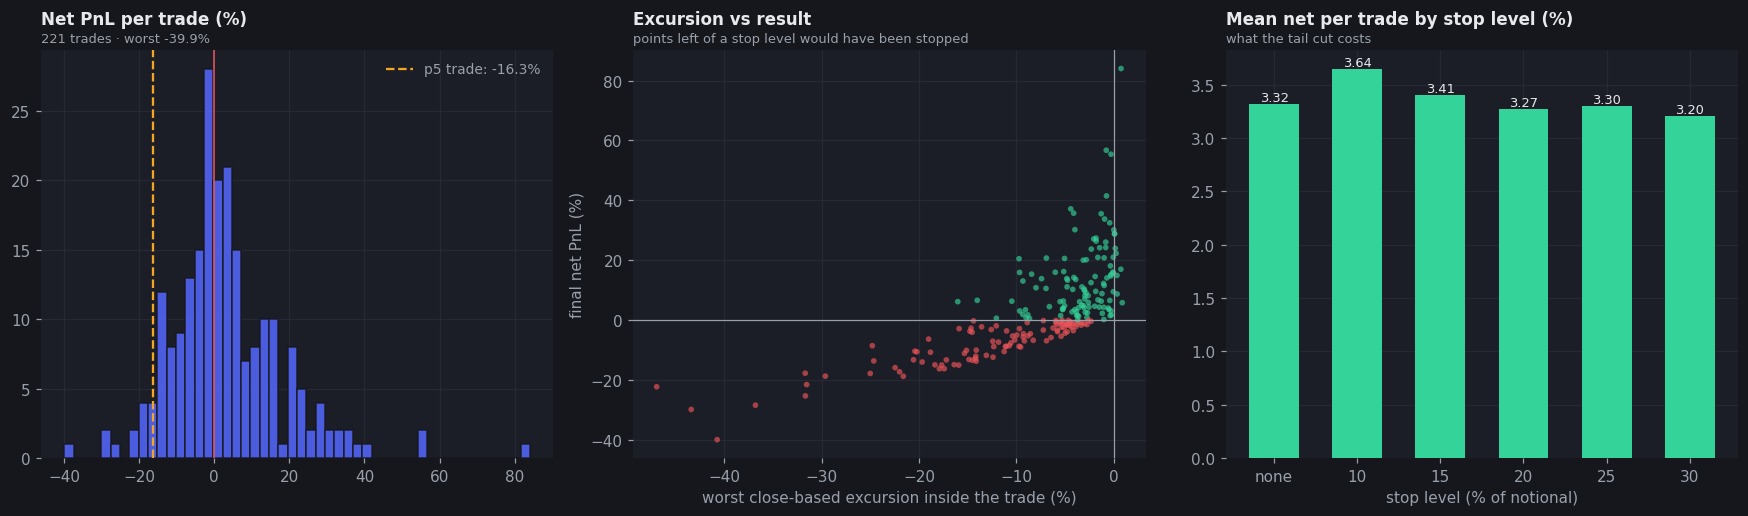

   [INFO] approximate stop test (informational)  ->  worst trade -39.9% without stop; best mean +3.64% at stop 10


'INFO'

In [9]:
# ---- tail / stop test (approximation: 1 h closes of the MTM path, fill at the stop level, % of the entry notional) ----
mp = eng.trade_mtm_paths(df, trades_all, sizing="capital")
mae = np.array([(np.cumprod(1 + p).min() - 1) * 100 for p in mp])            # worst close-based excursion inside each trade
pnl0 = trades_all["pnl"].to_numpy(float)
rows_s = []
for s_ in STOPS:
    p_ = pnl0 if s_ == 0 else np.where(mae <= -s_, -float(s_), pnl0)
    rows_s.append({"Stop %": "none" if s_ == 0 else s_, "Mean net %": p_.mean(), "PF": pf_np(p_), "Worst trade %": p_.min(),
                   "Stopped trades": 0 if s_ == 0 else int((mae <= -s_).sum()), "t-stat": tstat(p_)})
stop_tbl = pd.DataFrame(rows_s).set_index("Stop %")
print("=" * 70); print("APPROXIMATE STOP TEST (the rule has no stop; informational)"); print("=" * 70)
display(stop_tbl.round(3))

fig, (ax1, ax2, ax3) = subplots(1, 3, figsize=(16, 4.8))
ax1.hist(pnl0, bins=50, color=BLUE, alpha=0.85, edgecolor=BG); ax1.axvline(0, color=RED, lw=1)
ax1.axvline(float(np.percentile(pnl0, 5)), color=ORANGE, ls="--", label=f"p5 trade: {np.percentile(pnl0, 5):.1f}%"); legend(ax1, "upper right")
set_title(ax1, "Net PnL per trade (%)", f"{len(pnl0)} trades · worst {pnl0.min():.1f}%")
ax2.scatter(mae, pnl0, s=14, c=[GREEN if v > 0 else RED for v in pnl0], alpha=0.65, edgecolors="none")
ax2.axhline(0, color=SUB, lw=0.8); ax2.axvline(0, color=SUB, lw=0.8)
ax2.set_xlabel("worst close-based excursion inside the trade (%)"); ax2.set_ylabel("final net PnL (%)")
set_title(ax2, "Excursion vs result", "points left of a stop level would have been stopped")
lab = [str(i) for i in stop_tbl.index]
ax3.bar(range(len(lab)), stop_tbl["Mean net %"], color=[GREEN if v > 0 else RED for v in stop_tbl["Mean net %"]], width=0.6)
ax3.set_xticks(range(len(lab))); ax3.set_xticklabels(lab); ax3.set_xlabel("stop level (% of notional)")
for i, v in enumerate(stop_tbl["Mean net %"]):
    ax3.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=TXT)
set_title(ax3, "Mean net per trade by stop level (%)", "what the tail cut costs")
plt.tight_layout(); plt.show()
check.info("6 Stress", "approximate stop test (informational)", f"worst trade {pnl0.min():.1f}% without stop; best mean {stop_tbl['Mean net %'].max():+.2f}% at stop {stop_tbl['Mean net %'].idxmax()}")

## 7. EDGE DECAY & TEMPORAL STABILITY

Rolling mean and PF over the last 40 trades, PF by year and the **z wear-and-tear protocol**: z of the mean of the last 20 traded weeks against the in-sample reference (green > -1, yellow -1 to -2, red < -2). The ratio of recent (last 3 years) to historical expectancy is a **check** here, as in the Gotobi battery.

PF by year:


,n,pf,expectancy,win_rate,total_pnl
year,,,,,
2019,26,1.219,1.062,0.423,27.609
2020,37,3.075,5.968,0.703,220.829
2021,36,2.949,8.969,0.639,322.876
2022,14,0.648,-2.355,0.286,-32.975
2023,34,1.251,0.632,0.529,21.495
2024,28,1.656,2.597,0.464,72.724
2025,20,2.105,3.909,0.500,78.173
2026,26,1.324,0.843,0.423,21.912


Recent years [2023, 2024, 2025] PF 1.645 vs historical PF 2.094 | expectancy ratio 0.44 | decay warning: True

Reference (trades closed before OOS): mu0 = +3.808%, sigma0 = 16.317%, n = 147
z today = -0.64 (green) | minimum z = -2.08 on 2026-05-21
Traded weeks since OOS start by zone: {'green': 63, 'yellow': 9, 'red': 2}


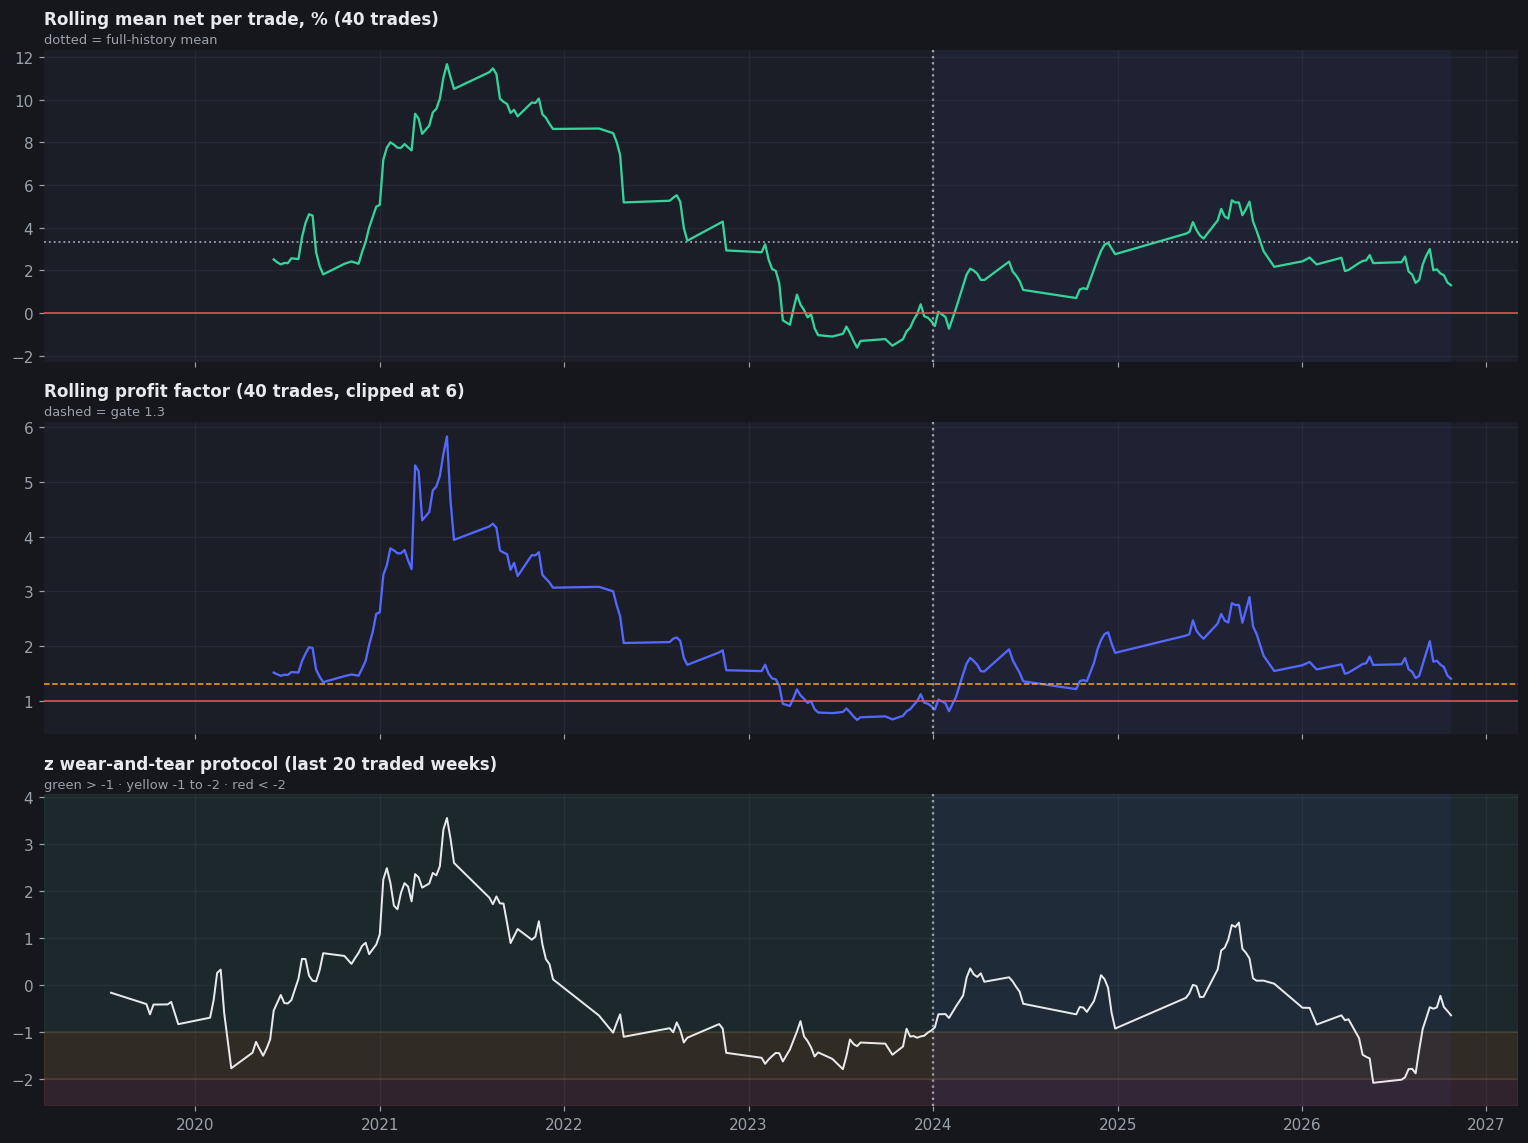


CHECKS (7):
   [FAIL] recent 3 years / historical expectancy >= 0.5  ->  0.44
   [PASS] z today not red (> -2)  ->  z -0.64 (green)
   [PASS] positive years >= 75% (full history)  ->  7/8


'PASS'

In [10]:
py = pf_by_year(trades_all)
print("PF by year:"); display(py.round(3))
ed = edge_decay_summary(trades_all)
print(f"Recent years {ed['recent_years']} PF {ed['recent']['pf']:.3f} vs historical PF {ed['historical']['pf']:.3f} | "
      f"expectancy ratio {ed['expectancy_ratio']:.2f} | decay warning: {ed['warning']}")

W, ROLL = 20, 40
ref = trades_all.loc[pd.to_datetime(trades_all["exit_time"]) < OOS_START, "pnl"]
mu0, sd0 = float(ref.mean()), float(ref.std(ddof=1))
s = trades_all.set_index(pd.to_datetime(trades_all["exit_time"]))["pnl"]
z = (s.rolling(W).mean() - mu0) / (sd0 / np.sqrt(W))
zc = z.dropna()
zone = pd.cut(zc, [-np.inf, -2, -1, np.inf], labels=["red", "yellow", "green"])
after = zone[zc.index >= oos_start]
print(f"\nReference (trades closed before OOS): mu0 = {mu0:+.3f}%, sigma0 = {sd0:.3f}%, n = {len(ref)}")
print(f"z today = {zc.iloc[-1]:+.2f} ({zone.iloc[-1]}) | minimum z = {zc.min():+.2f} on {zc.idxmin():%Y-%m-%d}")
print(f"Traded weeks since OOS start by zone: {after.value_counts().to_dict()}")

roll_mean = s.rolling(ROLL).mean()
roll_pf = s.rolling(ROLL).apply(pf_np, raw=True)
fig, (ax1, ax2, ax3) = subplots(3, 1, figsize=(14, 10.5), sharex=True)
ax1.plot(roll_mean.index, roll_mean, color=GREEN, lw=1.5); ax1.axhline(0, color=RED, lw=1); ax1.axhline(float(s.mean()), color=SUB, ls=":", lw=1.2)
ax2.plot(roll_pf.index, roll_pf.clip(upper=6), color=BLUE, lw=1.5); ax2.axhline(1, color=RED, lw=1); ax2.axhline(PF_MIN, color=ORANGE, ls="--", lw=1)
ax3.plot(zc.index, zc, color=TXT, lw=1.3)
lo_, hi_ = min(float(zc.min()) - 0.5, -2.5), max(float(zc.max()) + 0.5, 1.5)
ax3.axhspan(-1, hi_, color=GREEN, alpha=0.06); ax3.axhspan(-2, -1, color=ORANGE, alpha=0.10); ax3.axhspan(lo_, -2, color=RED, alpha=0.10); ax3.set_ylim(lo_, hi_)
for ax in (ax1, ax2, ax3):
    ax.axvspan(oos_start, s.index[-1], color=BLUE, alpha=0.06, lw=0); ax.axvline(oos_start, color=SUB, ls=":")
set_title(ax1, f"Rolling mean net per trade, % ({ROLL} trades)", "dotted = full-history mean"); set_title(ax2, f"Rolling profit factor ({ROLL} trades, clipped at 6)", f"dashed = gate {PF_MIN}")
set_title(ax3, f"z wear-and-tear protocol (last {W} traded weeks)", "green > -1 · yellow -1 to -2 · red < -2")
plt.tight_layout(); plt.show()

yr_mean = trades_all.groupby("year")["pnl"].mean()
pos_years = int((yr_mean > 0).sum())
print("\nCHECKS (7):")
check("7 Decay", f"recent 3 years / historical expectancy >= {DECAY_MIN:g}", bool(np.isfinite(ed["expectancy_ratio"]) and ed["expectancy_ratio"] >= DECAY_MIN), f"{ed['expectancy_ratio']:.2f}")
check("7 Decay", "z today not red (> -2)", bool(zc.iloc[-1] > -2), f"z {zc.iloc[-1]:+.2f} ({zone.iloc[-1]})")
check("7 Decay", "positive years >= 75% (full history)", pos_years >= 0.75 * len(yr_mean), f"{pos_years}/{len(yr_mean)}")

## 8. FULL VALIDATION GATE RUN (AUTOMATED MULTI-PHASE AUDIT)

`validation_gate.run_validation` on the frozen rules, at the robot's size (official verdict) and at 2x (for transparency). Four phases: OOS, Monte Carlo, monkey and plateau; edge decay is informational.

In [11]:
COMMON_START = max(d.index[d["mom_ret"].notna()][0] for d in preps.values())
def run_cell(L, H):
    t = eng.run_weekly_backtest(preps[L], lookback_days=L, hold_days=H, **{k: v for k, v in RULES.items() if k not in ("lookback_days", "hold_days")})
    et, xt = pd.to_datetime(t["entry_time"]), pd.to_datetime(t["exit_time"])
    return t[(et >= COMMON_START) & (xt <= OOS_START)]
def evaluate_gate(L, H):
    t = run_cell(L, H)
    return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))
pf_grid, n_grid = grid_search(evaluate_gate, LOOKBACKS, HOLDS)
print("validation_gate.DEFAULTS in use:", GATE)

# Monkey costs per side = spread + half of the weekly swap, so the gate's monkey pays what the strategy pays
cost_side_pct = float((trades_all["cost_pct"].mean() - trades_all["swap_pct"].mean()) / 2.0)
print(f"Cost per side passed to the gate's monkey: {cost_side_pct:.3f}%")

elig_A = pd.Series(True, index=df.index)
validations = {}
for i, (k_, f) in enumerate(SIZES.items(), 1):
    print("\n" + "=" * 70); print(f"{i}. VALIDATION GATE: {k_} SIZING" + (" (OFFICIAL VERDICT)" if k_ == OFFICIAL else " (FOR TRANSPARENCY)")); print("=" * 70)
    try:
        validations[k_] = run_validation(
            trades_df=scaled(trades_all, f), df_prices=df, eligible=elig_A, grid_pf=pf_grid, grid_n=n_grid, chosen=CHOSEN,
            oos_start=oos_start, mode="compound", mtm_paths=paths[k_],
            monkey_entry_col="open", monkey_exit_col="open", monkey_cost_pct_per_side=cost_side_pct, verbose=True)
    except Exception as e:
        print(f"run_validation failed for {k_}: {type(e).__name__}: {e}")
validation = validations.get(OFFICIAL)

validation_gate.DEFAULTS in use: {'n_min': 30, 'pf_min': 1.3, 'mdd_min': -0.2, 'block': 5, 'mc_ret_p5_min': 0.0, 'mc_mdd_p5_min': -0.25, 'mc_ruin_max': 0.05, 'monkey_pct_min': 0.95, 'plateau_pf_min': 1.3, 'plateau_n_min': 30, 'plateau_max_drop': 30}
Cost per side passed to the gate's monkey: 0.378%

1. VALIDATION GATE: 5% (robot) SIZING (OFFICIAL VERDICT)
VALIDATION GATE
[PASS] 1_oos: {'n': 72, 'pf': np.float64(1.646), 'pf_without_best_trade': np.float64(1.496), 'max_dd': -0.045, 'dd_basis': 'mtm'}
[PASS] 2_monte_carlo: {'ret_p5': 0.169, 'mdd_p5': -0.099, 'prob_ruin': 0.0, 'dd_basis': 'mtm'}
[PASS] 3_monkey: {'pf_real': 1.886, 'pct_pf': 0.983}
[PASS] 4_plateau: {'center_pf': 1.989, 'plateau': True, 'worst_drop_pct': 13.704}
[INFO] 5_edge_decay: {'recent_pf': 1.645, 'historical_pf': 2.094, 'warning': True}
------------------------------------------------------------ 
OVERALL: PASSED

2. VALIDATION GATE: 10% (2x robot) SIZING (FOR TRANSPARENCY)
VALIDATION GATE
[PASS] 1_oos: {'n': 72, 'pf

## 9. STRATEGY METRICS, PASS / FAIL SUMMARY AND VERDICT

In [12]:
ret_series = eng.daily_returns(df, trades_all, sizing="fraction")
eq_series = (1.0 + ret_series).cumprod()
metrics = {"sharpe": float(sharpe_ratio(ret_series, periods_per_year=PPY)), "max_drawdown": float(max_drawdown(eq_series)), "num_trades": int(len(trades_all))}
print("=" * 70); print(f"FINAL STRATEGY METRICS ({OFFICIAL} SIZING, WHOLE PERIOD)"); print("=" * 70)
print(f"Sharpe Ratio : {metrics['sharpe']:.2f}\nMax Drawdown : {metrics['max_drawdown'] * 100:.2f}%\nTotal Trades : {metrics['num_trades']}")

def tag(p):
    return "INFO" if p.get("informational") else ("SKIP" if p.get("skipped") else ("PASS" if p["passed"] else "FAIL"))
chk = C.frame()
cnt = C.counts()
print("\n" + "=" * 70); print("PASS / FAIL SUMMARY"); print("=" * 70)
display(style_status(chk))

if validation is not None:
    print(f"\nValidation Gate Overall ({OFFICIAL}): {validation['status']}")
    for name, p in validation["phases"].items():
        print(f"   [{tag(p)}] {name}")
    for k_, v in validations.items():
        print(f"   Gate at {k_}: {v['status']} (failed: {[n for n, p in v['phases'].items() if 'passed' in p and not p['passed']]})")
else:
    print("\nValidation gate did not run (see section 8): the verdict below uses only the checks of this notebook.")

# ---- weaknesses that notebook 02 carried over: declared here, not silently ignored ----
try:
    s02 = json.load(open(Path(RUN_DIR) / "02_plateau.json", encoding="utf-8"))
except FileNotFoundError:
    s02 = None
weak02 = []
if s02 is not None:
    weak02 = [c_["name"] for c_ in s02.get("checks", []) if c_.get("status") == "FAIL"]
    if not s02.get("checks"):                                   # notebook 02 saved before the checks table existed
        if not s02.get("plateau_without_bull_years", {}).get("passed", True):
            weak02.append("plateau without the bull years (diagnostic)")
        if s02.get("dose_response", {}).get("p", 0) >= 0.05:
            weak02.append("dose-response p >= 0.05")
print("\nWEAKNESSES CARRIED OVER FROM NOTEBOOK 02 (declared, not hidden):")
for w_ in (weak02 or (["none"] if s02 is not None else ["notebook 02 results not found"])):
    print("   - " + w_)

gate_ok = bool(validation["passed"]) if validation is not None else None
failed = chk.loc[chk["status"] == "FAIL", "name"].tolist()
print("\n" + "=" * 70); print("VERDICT"); print("=" * 70)
print(f"PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | SKIP {cnt['SKIP']} | INFO {cnt['INFO']} | gate {'PASSED' if gate_ok else ('FAILED' if gate_ok is not None else 'not run')}")
print(f"OOS: PF {m_oos['profit_factor']:.3f} | t {t_oos_:.2f} plain / {t_oos_h:.2f} overlap-adjusted | {len(trades_oos)} trades | z today {zc.iloc[-1]:+.2f} ({zone.iloc[-1]})")
print(f"Capital {CAPITAL:,.0f}: lot-adjusted size {EFF_FRAC:.1%} per trade | MC worst-5% DD {mc0['mdd_p5'] * 100:.2f}% at the robot size, {mc_lot['mdd_p5'] * 100:.2f}% at the real size | cost break-even {be_all:.1f}x")
if gate_ok and not failed:
    print("OVERALL: gate and checks PASS. Edge confirmed for the next stage as a CONDITIONAL candidate (trial 2, OOS not independent): it needs forward / demo data.")
else:
    print(f"OVERALL: NOT confirmed. Gate: {'PASSED' if gate_ok else 'FAILED / not run'}. Failed checks ({len(failed)}): {failed}. "
          "Do not promote without documenting them (a margin or exception must be declared, not silently applied); do not re-tune the parameters.")

FINAL STRATEGY METRICS (5% (robot) SIZING, WHOLE PERIOD)
Sharpe Ratio : 0.92
Max Drawdown : -5.82%
Total Trades : 221

PASS / FAIL SUMMARY


,section,name,status,detail
0,2 OOS,N OOS >= 30,PASS,72 trades
1,2 OOS,PF net OOS >= 1.3,PASS,1.646
2,2 OOS,t net OOS (overlap-adjusted) >= 1.645,FAIL,"1.39 (plain 1.49, one-sided 5 %)"
3,2 OOS,hard limit at the ideal fraction (full period),PASS,max DD -6.55% vs -9%
4,2 OOS,"hard limit lot-adjusted at capital 3,500",PASS,max DD -8.80% | headroom +0.20 pts
5,3 Walk-forward,efficiency >= 0.5,PASS,0.55
6,3 Walk-forward,positive OOS years >= 60%,PASS,100% (4/4)
7,3 Walk-forward,worst-year OOS drawdown inside -20% (gate),PASS,-3.84%
8,3 Walk-forward,worst-year OOS drawdown inside the hard limit (-9%),PASS,-3.84%
9,4 Monte Carlo,worst-5% DD inside the gate limit (-25%),PASS,-9.89% at 5% (robot)



Validation Gate Overall (5% (robot)): PASSED
   [PASS] 1_oos
   [PASS] 2_monte_carlo
   [PASS] 3_monkey
   [PASS] 4_plateau
   [INFO] 5_edge_decay
   Gate at 5% (robot): PASSED (failed: [])
   Gate at 10% (2x robot): PASSED (failed: [])

WEAKNESSES CARRIED OVER FROM NOTEBOOK 02 (declared, not hidden):
   - plateau without the bull years (diagnostic)
   - dose-response p >= 0.05

VERDICT
PASS 20 | FAIL 5 | SKIP 0 | INFO 2 | gate PASSED
OOS: PF 1.646 | t 1.49 plain / 1.39 overlap-adjusted | 72 trades | z today -0.64 (green)
Capital 3,500: lot-adjusted size 5.5% per trade | MC worst-5% DD -9.89% at the robot size, -13.53% at the real size | cost break-even 5.4x
OVERALL: NOT confirmed. Gate: PASSED. Failed checks (5): ['t net OOS (overlap-adjusted) >= 1.645', 'worst-5% DD inside the hard limit (-9%) at the robot size', 'worst-5% DD inside the hard limit at the real lot-adjusted size (capital 3,500)', 'without the best 10% of trades: mean net >= 0', 'recent 3 years / historical expectancy 

## 10. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [13]:
def _scalars(p):
    return {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, np.generic))}

save_json(cfg, "03_validation.json", {
    "variant": cfg["id"], "ticker": TICKER, "params": cfg["params"], "oos_start": str(oos_start.date()),
    "official_sizing": OFFICIAL, "n_trials": N_TRIALS,
    "status": {k_: v["status"] for k_, v in validations.items()},
    "metrics": metrics,
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"]), "t_stat": float(t_oos_), "pf_without_best": float(pf_oos_nb)},
    "hard_limit": hl_tbl.round(3).reset_index().to_dict(orient="records"),
    "phases": {k_: {n: _scalars(p) for n, p in v["phases"].items()} for k_, v in validations.items()},
    "walk_forward": {"efficiency": float(efficiency), "pct_positive_years": pct_positive_years, "worst_mdd": worst_oos_mdd, "passed": wf_pass},
    "monkey": {"A_pct_pf": mk_A["pct_pf"], "B_pct_pf": mk_B["pct_pf"], "B_required": B_LEVEL},
    "monte_carlo_mdd_p5": {k_: m["mdd_p5"] for k_, m in mcs.items()},
    "cost_sweep": cost_tbl.reset_index().to_dict(orient="records"),
    "cost_breakeven_multiple": {"spread_and_swap": float(be_all), "swap_only": float(be_swap)},
    "profit_share_top10pct_trades": share_top10,
    "z_protocol": {"mu0": mu0, "sigma0": sd0, "z_today": float(zc.iloc[-1]), "zone_today": str(zone.iloc[-1]), "z_min": float(zc.min())},
    "edge_decay_warning": bool(ed["warning"]), "stress_ok": stress_ok,
    "capital": CAPITAL, "lot_adjusted_fraction": EFF_FRAC,
    "monte_carlo_lot_adjusted_mdd_p5": float(mc_lot["mdd_p5"]),
    "t_overlap_adjusted": {"is": float(t_is_h), "oos": float(t_oos_h), "full": float(t_full_h), "lags": LAGS},
    "bonferroni_bar": {"trials": bonferroni(N_TRIALS), "yaml": bonferroni(K_HYP), "grid": bonferroni(K_GRID)},
    "weaknesses_from_02": weak02, "checks": chk.to_dict(orient="records"),
    "counts": cnt, "overall_failed": failed,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/03_validation.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/03_validation.json')